
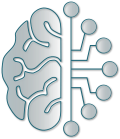

**Environment initialized:** Monday 19 October 2026, 17:14:46 on localhost.localdomain

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
##############################################
##### for development only                   #
# %load_ext autoreload                       #
# %autoreload 2                              #
##############################################

import pyphyschemtools as t4pPC
from pyphyschemtools import fg, hl, bg, color

t4pPC.init('t4pPC')
%matplotlib inline

# get_ppct_data() is a helper function made to easily retrieve absolute paths for built-in example files (XYZ, Excel, etc.)
# that are available in the data_examples/ subfolder as part of the pyphyschemtools library

# This get_ppct_data() utility is specifically designed for accessing built-in example data bundled
# with pyphyschemtools. For your own local files, please use standard Python paths or pathlib

from pyphyschemtools import get_ppct_data

%load_ext autoreload
%autoreload 2

21 points lus.


,Time / s,Aext
0,0.0,0.665710
1,15.0,0.643990
2,30.0,0.624290
3,45.0,0.604767
4,60.0,0.586594
5,75.0,0.569031
6,90.0,0.551697
7,105.0,0.535538
8,120.0,0.520119
9,135.0,0.505089


Ordre 1 : k optimal = 1.9952e-03  (RMSD = 3.2229e-03)  (t1/2 = 3.4741e+02)


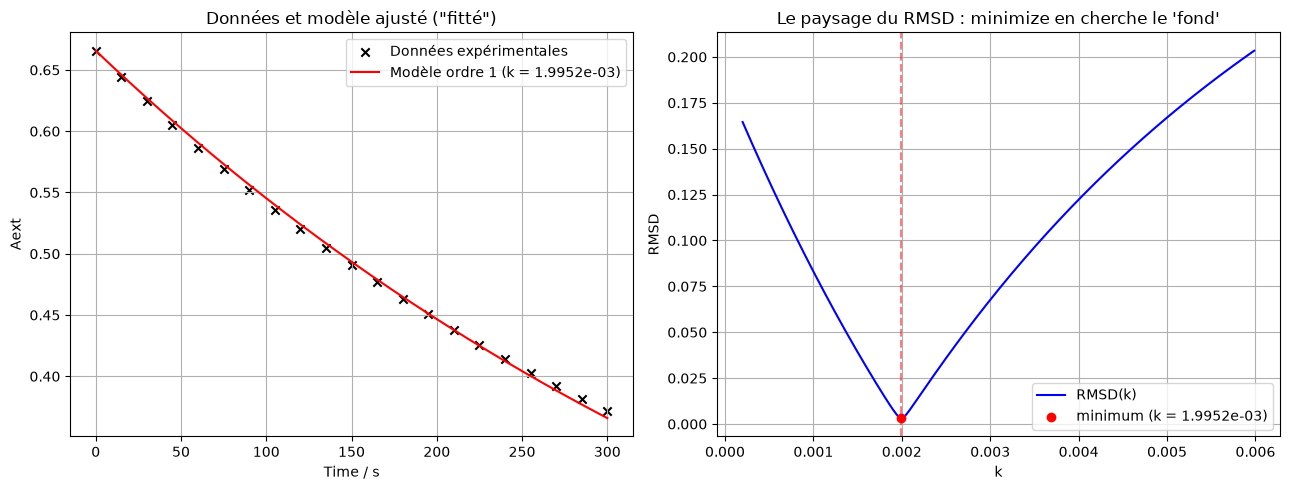

In [17]:
from pyphyschemtools import kbasic

# 1) Lire les données (fichier Excel à deux colonnes : temps, G)
kb = kbasic()
file = get_ppct_data("Kinetics/kbasic.xlsx")
kb.read(file)        # sur Google Colab : kb.read(colab=True)

# 2) Faire le fit pour l'ordre voulu
kb.fit(ordre=1)                # affiche k optimal et le RMSD

# 3) Tracer le résultat (données + modèle, et paysage du RMSD)
kb.plot()

Experiments detected: 1
✅ Loaded: Abs (Exp 1)
   [Parameters from Abs] a0: 2.5000e-04 mol.L-1 | alpha: 2.0 | beta: 1.0



,Temps / s,Abs
3,0,1.400
4,7.593,1.330
5,15.179,1.270
6,22.764,1.210
7,30.347,1.160
...,...,...
62,466.587,0.378
63,476.19,0.377
64,485.881,0.375
65,495.584,0.374


--- Order 0 ---
  GUESS: k: 9.09e-07 | Y0: 1.4000 | Yinf: 0.3730 | binf: 1.250e-04
  OPTIM: k: 6.13e-07 | Y0: 1.2710 | Yinf: 0.4252 | binf: 1.250e-04
  ✅ RMSE: 4.94e-02
       R2: 0.97
      AIC: -379.00 (lower is better)
      BIC: -372.52 (more strict on complexity)
--- Order 1 ---
  GUESS: k: 3.64e-03 | Y0: 1.4000 | Yinf: 0.3730
  OPTIM: k: 4.33e-03 | Y0: 1.3989 | Yinf: 0.3596
  ✅ RMSE: 8.77e-04
       R2: 1.00
      AIC: -895.00 (lower is better)
      BIC: -888.53 (more strict on complexity)
--- Order 2 ---
  GUESS: k: 1.45e+01 | Y0: 1.4000 | Yinf: 0.3730 | binf: 1.250e-04
  OPTIM: k: 1.97e+01 | Y0: 1.4449 | Yinf: 0.1145 | binf: 1.250e-04
  ✅ RMSE: 1.85e-02
       R2: 1.00
      AIC: -504.88 (lower is better)
      BIC: -498.41 (more strict on complexity)
--- KORD CONCLUSION ---
Best model: ORDER 1
Initial concentration a0: 2.500e-04 mol.L-1
alpha: 2.0
beta: 1.0

metrics
RMSE: 0.001
  R2: 1.000

Y_exp(t=0): 1.400e+00
Y_fit(t=0): 1.399e+00
Y_fit(t=inf): 3.596e-01

k_fit: 4.334e-03


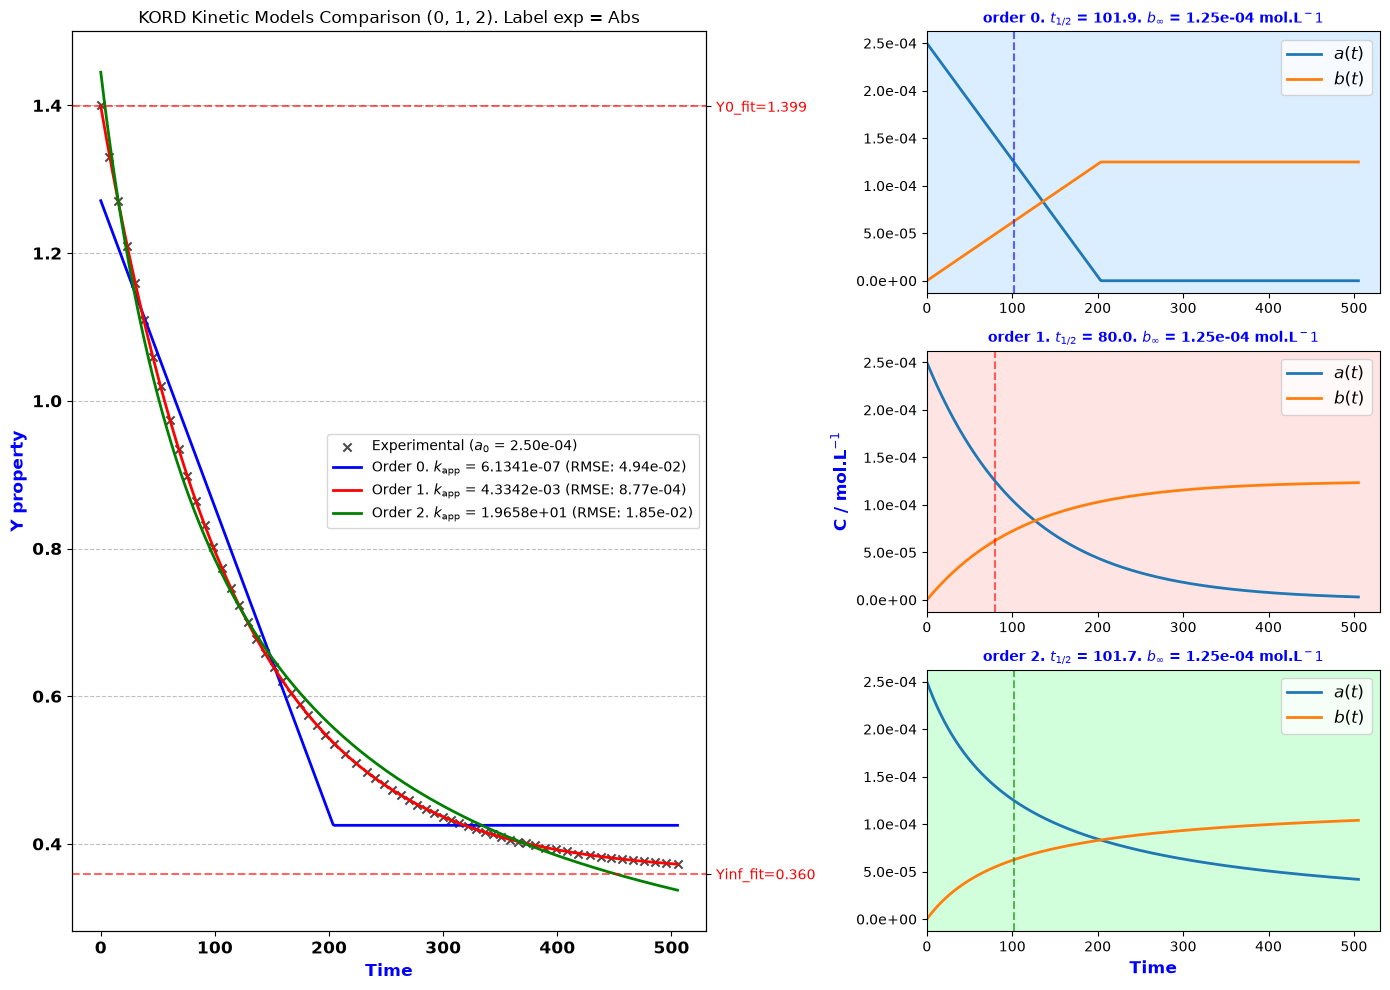

In [63]:
from pyphyschemtools import KORD, get_ppct_data

# Load a bundled example file (experiment 1) and build the KORD instance in one call:
file = get_ppct_data("Kinetics/Test_Examples_VP.ods")
study1 = KORD.from_spreadsheet(file, exp_number=1, sheet_name=0)

study1.get_best_order()      # fits orders 0, 1, 2 and reports the best one
study1.plot_all_fits()       # visual comparison of the three fits

Experiments detected: 1
✅ Loaded: Abs (Exp 1)
   [Parameters from Abs] a0: 2.0000e-05 mol.L-1 | alpha: 1.0 | beta: 1.0



,Temps / s,Abs
3,0,1.600
4,7.593,1.560
5,15.179,1.530
6,22.764,1.490
7,30.347,1.460
...,...,...
62,466.587,0.715
63,476.19,0.709
64,485.881,0.702
65,495.584,0.696


--- Order 0 ---
  GUESS: k: 9.66e-08 | Y0: 1.6000 | Yinf: 0.6900 | binf: 2.000e-05
  OPTIM: k: 7.06e-08 | Y0: 1.5164 | Yinf: 0.7907 | binf: 2.000e-05
  ✅ RMSE: 4.86e-02
       R2: 0.96
      AIC: -380.99 (lower is better)
      BIC: -374.51 (more strict on complexity)
--- Order 1 ---
  GUESS: k: 4.83e-03 | Y0: 1.6000 | Yinf: 0.6900
  OPTIM: k: 4.38e-03 | Y0: 1.5817 | Yinf: 0.5937
  ✅ RMSE: 6.22e-03
       R2: 1.00
      AIC: -644.18 (lower is better)
      BIC: -637.70 (more strict on complexity)
--- Order 2 ---
  GUESS: k: 2.41e+02 | Y0: 1.6000 | Yinf: 0.6900 | binf: 2.000e-05
  OPTIM: k: 1.84e+02 | Y0: 1.5998 | Yinf: 0.1988 | binf: 2.000e-05
  ✅ RMSE: 1.69e-03
       R2: 1.00
      AIC: -811.01 (lower is better)
      BIC: -804.54 (more strict on complexity)
--- KORD CONCLUSION ---
Best model: ORDER 2
Initial concentration a0: 2.000e-05 mol.L-1
Fitted final concentration (b_inf): 2.000e-05 mol.L-1
a0 after binf = [B](inf): 2.000e-05 mol.L-1
alpha: 1.0
beta: 1.0

metrics
RMSE: 0.002
 

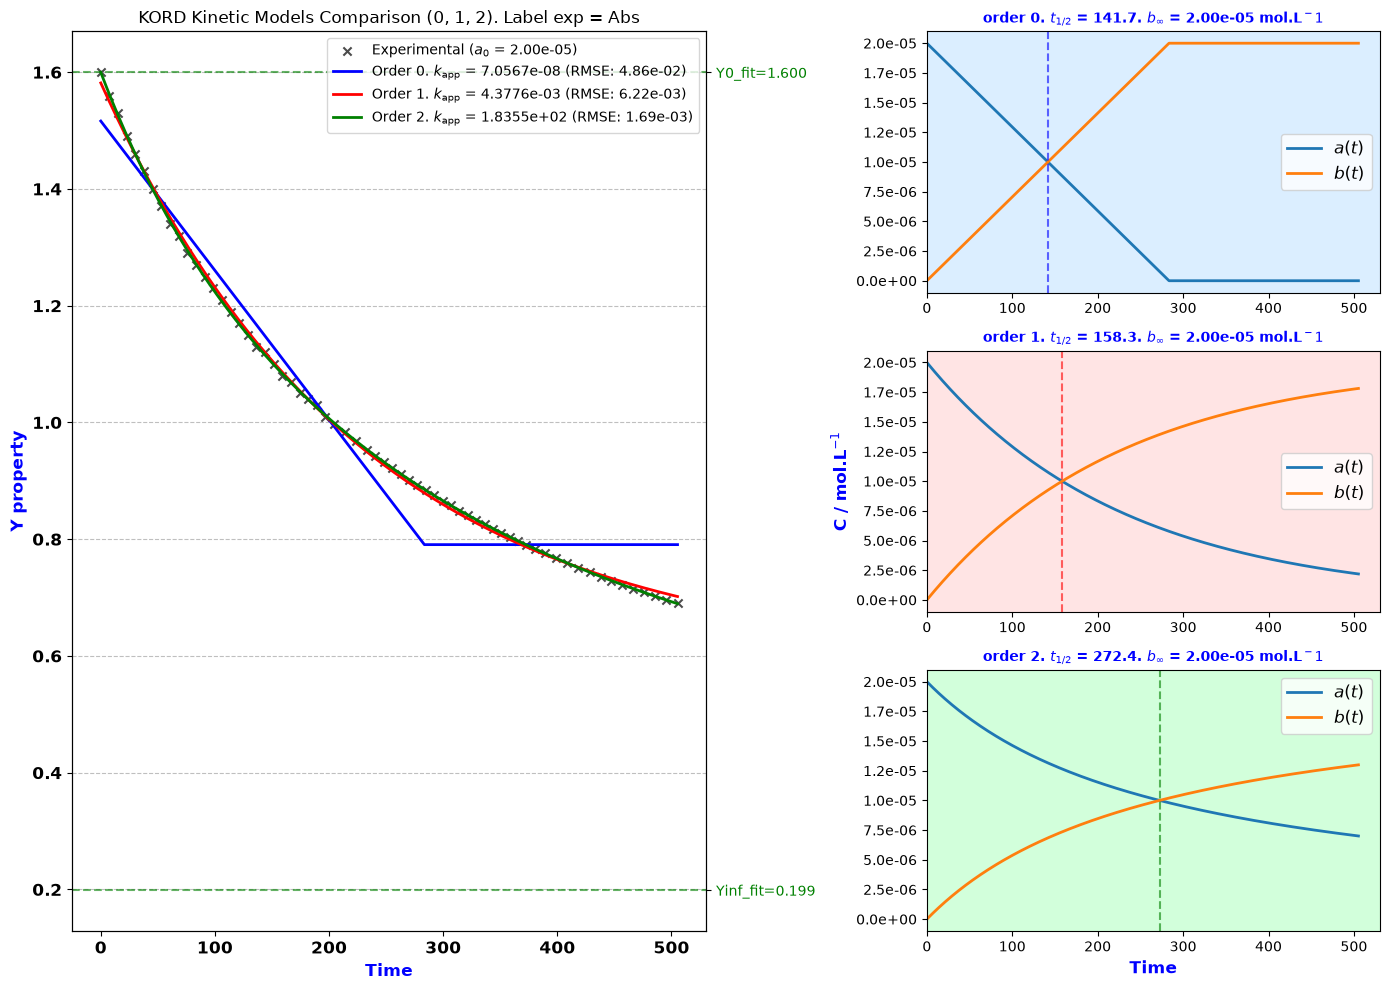

In [64]:
from pyphyschemtools import KORD, get_ppct_data

# Load a bundled example file (experiment 1) and build the KORD instance in one call:
file = get_ppct_data("Kinetics/Test_Examples_VP.ods")
study2 = KORD.from_spreadsheet(file, exp_number=1, sheet_name=1)

study2.get_best_order()      # fits orders 0, 1, 2 and reports the best one
study2.plot_all_fits()       # visual comparison of the three fits


--- Order 2 ---
  GUESS: k: 1.63e+02 | Y0: 1.6000 | Yinf: 0.2500 (fixed) | binf: 2.000e-05
  OPTIM: k: 2.02e+02 | Y0: 1.6101 | Yinf: 0.2500 (fixed) | binf: 2.000e-05
  ✅ RMSE: 4.59e-03
       R2: 1.00
      AIC: -685.18 (lower is better)
      BIC: -680.86 (more strict on complexity)
⚠️  Study 2: using the cached order-2 fit (fix_Y0=False, fix_Yinf=True), not the fix_Y0=False, fix_Yinf=False requested here.


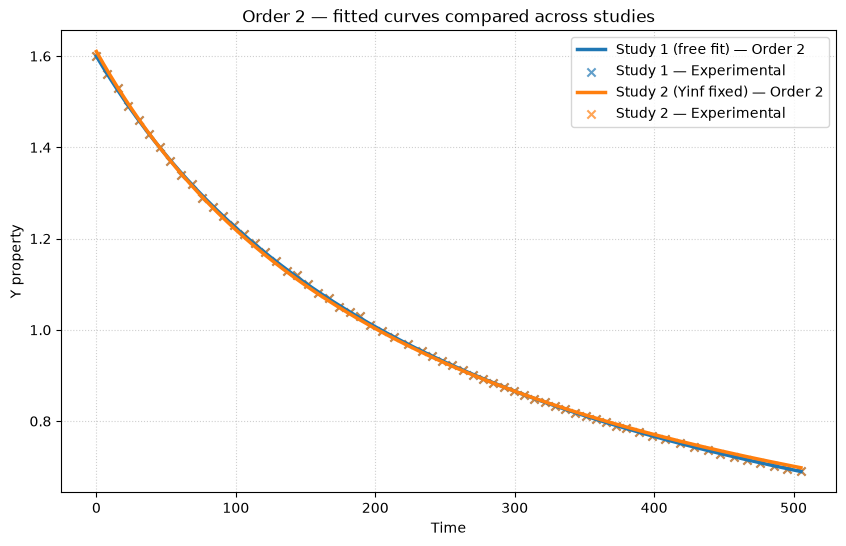

In [68]:
from pyphyschemtools import superpose_plots
study2bis = study2.copy()
study2bis.Yinf_guess=0.25
study2bis.fit(order=2, fix_Yinf=True, fix_Y0=False)
superpose_plots([study2, study2bis], order=2)